In [1]:
# run from scvi_env
import os
import sys
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scanpy as sc
import anndata as ad
# import rapids_singlecell as rsc
import scvi
import session_info

sys.path.append('/nfs/casm/team215mg/users/od5/scripts/')
from single_cell_utils import *
from scjp_colors import *

In [2]:
session_info.show()

/software/conda/users/od5/scvi_24/lib/python3.9/site-packages/session_info/main.py:213: UserWarning: The '__version__' attribute is deprecated and will be removed in MarkupSafe 3.1. Use feature detection, or `importlib.metadata.version("markupsafe")`, instead.
  mod_version = _find_version(mod.__version__)


In [6]:
work_dir = '/lustre/scratch125/casm/teams/team215/users/od5/projects/celltherapy/ipsc/multiome/gex_adata/tf_pilot/batch1/ipsc/'
os.makedirs(work_dir , exist_ok=True)

In [7]:
output_p = (work_dir + 'leiden_v1/')
os.makedirs(output_p, exist_ok=True)

### 1. Import adata object

In [8]:
## Load full dataset
adata = sc.read_h5ad((work_dir + 'adata_prefilter.h5ad'))

In [9]:
adata

AnnData object with n_obs × n_vars = 17276 × 36601
    obs: 'sample_barcode', 'barcode', 'gex_barcode', 'atac_barcode', 'cellranger_gex_umis_count', 'cellranger_gex_genes_count', 'snap_atac_fragments', 'snap_TSS_enrichment', 'f_intronic', 'cellranger_is_cell', 'EDM_is_cell', 'multiQC_leiden', 'multiQC_is_cell', 'atac_doublet_score', 'sample_ID', 'n_genes_by_counts', 'total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'amulet_pval', 'amulet_qval', 'enrichment', 'sample_description', 'Control_pos2', 'CEBPA_pos2', 'CEBPD_pos2', 'EBF1_pos2', 'FOXO3_pos2', 'HOPX_pos2', 'PRDM1_pos2', 'RUNX2_pos2', 'TBX21_pos2', 'TCF7_pos2', 'max', 'perturbation'
    uns: 'sample_ID_colors'
    layers: 'counts'

### 2. Clustering and UMAP

In [10]:
## Find neighbors, run Leiden clustering and UMAP

# Normalizing to median total counts
sc.pp.normalize_total(adata)

# Logarithmize the data
sc.pp.log1p(adata)

sc.pp.highly_variable_genes(adata)
sc.pp.pca(adata)

sc.pp.neighbors(adata)
sc.tl.leiden(adata, resolution=3)
sc.tl.umap(adata)

/tmp/ipykernel_2019869/2476384579.py:13: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata, resolution=3)


In [11]:
adata.write_h5ad((output_p + 'adata_leiden_v1.h5ad'))

In [12]:
adata = sc.read_h5ad((output_p + 'adata_leiden_v1.h5ad'))

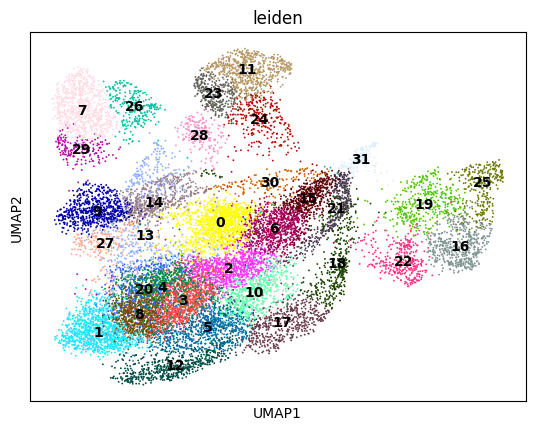

In [13]:
sc.pl.umap(adata, color=['leiden'], legend_loc='on data')

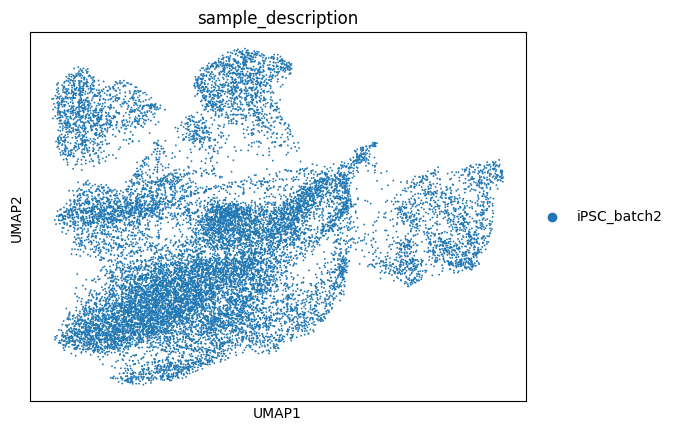

In [14]:
sc.pl.umap(adata, color=['sample_description'])

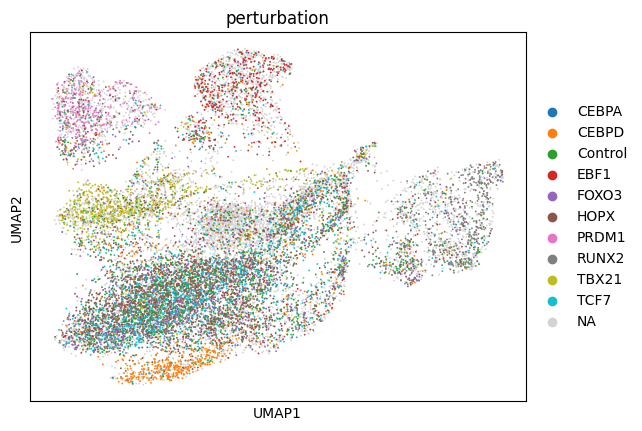

In [15]:
sc.pl.umap(adata, color=['perturbation'])

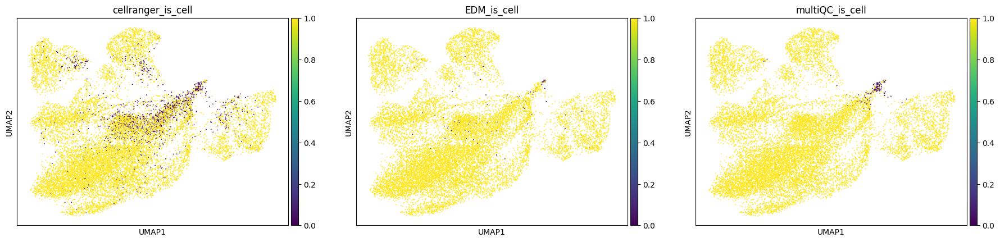

In [16]:
sc.pl.umap(adata, color=['cellranger_is_cell', 'EDM_is_cell', 'multiQC_is_cell'], vmax='p99')

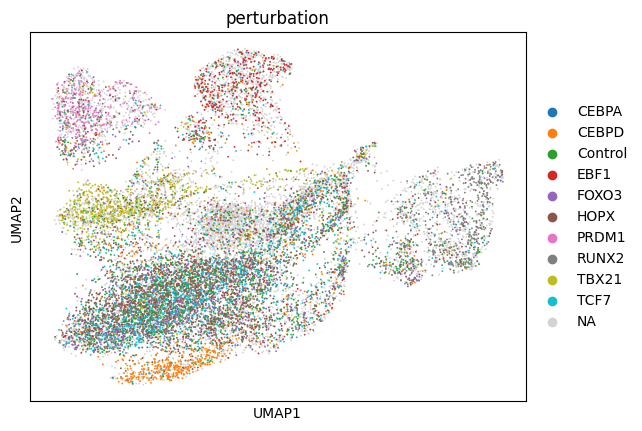

In [17]:
sc.pl.umap(adata, color=['perturbation'])

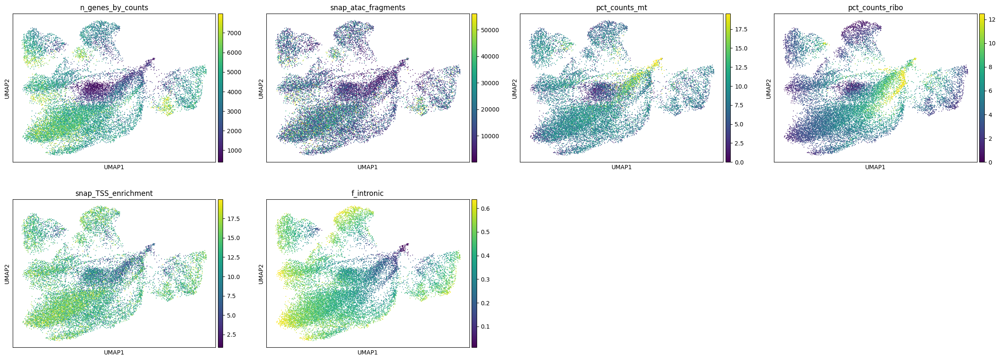

In [18]:
sc.pl.umap(adata, color=['n_genes_by_counts', 'snap_atac_fragments', 'pct_counts_mt', 'pct_counts_ribo', 'snap_TSS_enrichment', 'f_intronic'], vmax='p99')

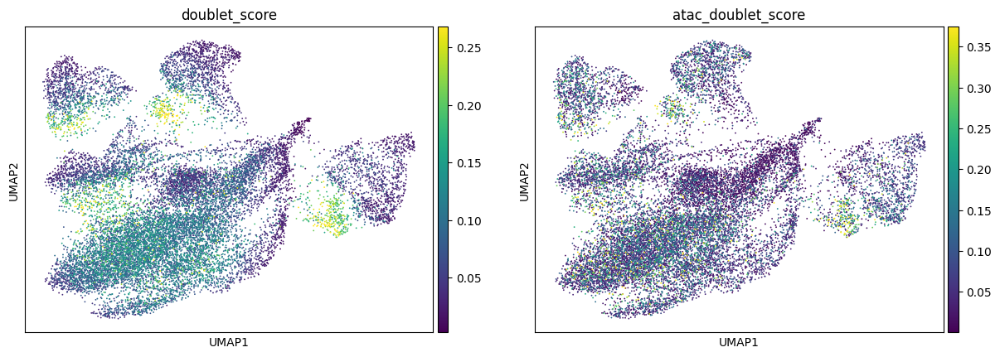

In [19]:
sc.pl.umap(adata, color=['doublet_score', 'atac_doublet_score'], vmax='p99')

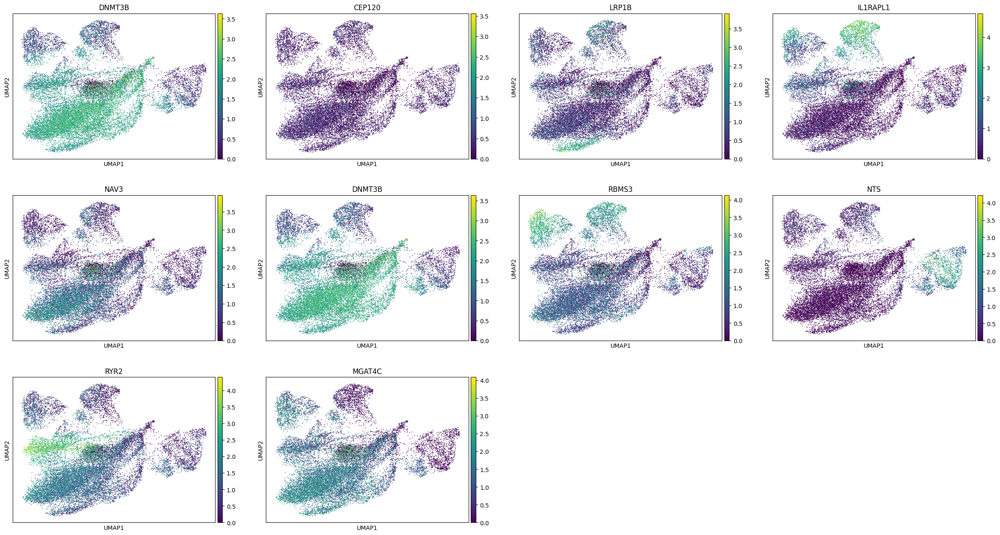

In [20]:
sc.pl.umap(adata, color=['DNMT3B', 'CEP120', 'LRP1B', 'IL1RAPL1', 'NAV3', 'DNMT3B', 'RBMS3', 'NTS', 'RYR2', 'MGAT4C'])

In [21]:
## Agreement in doublet scores between GEX and ATAC
from scipy.stats import pearsonr

pearsonr(adata.obs['doublet_score'], adata.obs['atac_doublet_score'])

PearsonRResult(statistic=0.25769035499152765, pvalue=4.3016462103414455e-260)

Text(0, 0.5, 'ATAC doublet score')

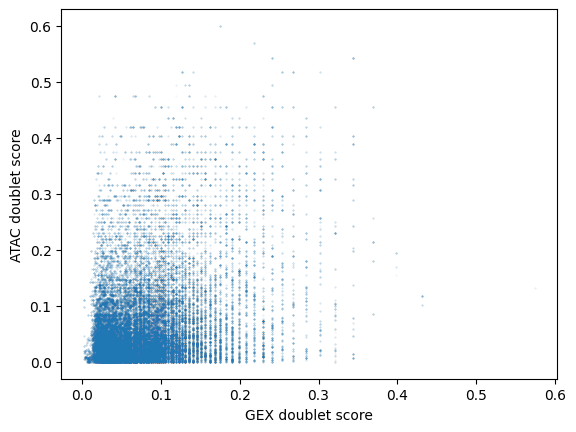

In [22]:
ridx = np.random.choice(range(adata.obs.shape[0]), 100000) 

plt.scatter(adata.obs['doublet_score'][ridx ], adata.obs['atac_doublet_score'][ridx ], s=0.1, alpha=0.1)
plt.xlabel('GEX doublet score')
plt.ylabel('ATAC doublet score')

In [23]:
adata.obs['amulet_doublet'] = (adata.obs['amulet_qval'] < 0.05).astype(str)

[<Axes: xlabel='amulet doublet', ylabel='doublet_score'>,
 <Axes: xlabel='amulet doublet', ylabel='atac_doublet_score'>]

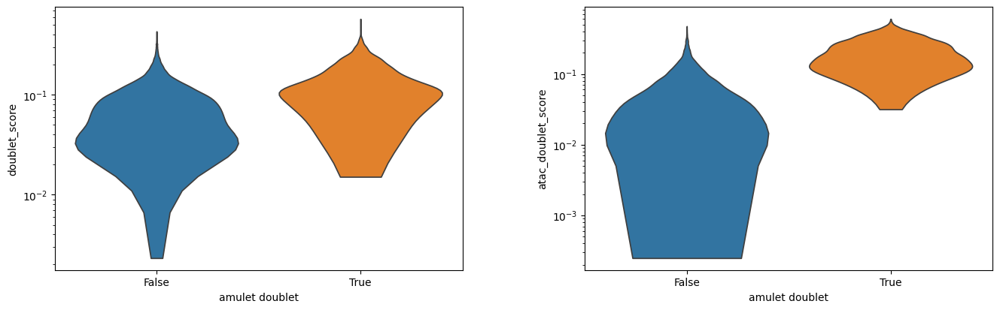

In [24]:
sc.pl.violin(adata, groupby='amulet_doublet', keys=['doublet_score', 'atac_doublet_score'], size=0, log=True, show=False)

In [25]:
# pd.crosstab(adata.obs['souporcell_status'], adata.obs['amulet_doublet'])

In [26]:
# ax = sc.pl.violin(adata[adata.obs['souporcell_status']=='doublet'], groupby='amulet_doublet', keys=['snap_atac_fragments'], size=0, log=True, show=False)
# ax.set_title('Souporcell doublets')
# plt.show()

In [27]:
# Cells with multiple genotypes or predicted by AMULET are high confidence doublets:
# adata.obs['is_valid_doublet'] = ((adata.obs['souporcell_status'].isin(['doublet', 'unassigned'])) | (adata.obs['amulet_doublet']=='True')).astype(int)
adata.obs['is_valid_doublet'] = (adata.obs['amulet_doublet']=='True').astype(int)

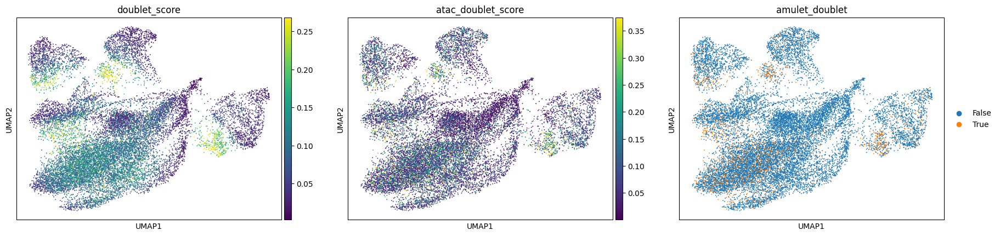

In [28]:
sc.pl.umap(adata, color=['doublet_score', 'atac_doublet_score', 'amulet_doublet'], vmax='p99')

In [29]:
## We see that the doublet scores broadly agree, but not always at the level of individual cells.
## However, doublets from multiple methods seem to concentrate around the same area of the embedding.

## The idea here is to use high resolution overclustering, then estimate average scores across methods and remove clusters with overall high scores in all of them.

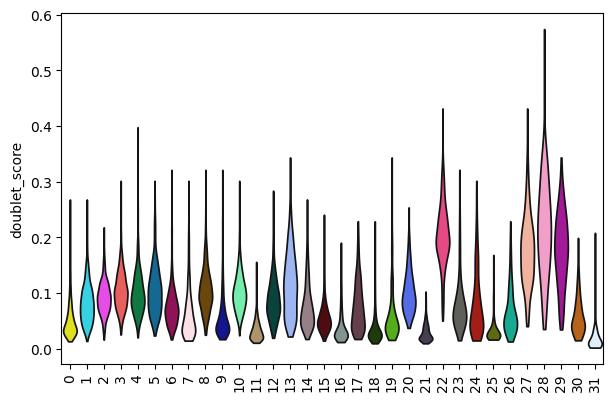

In [30]:
## We could in principle use our current level of clustering (leiden=3) but we see that there are many clusters that contain mixtures of doublets and singlets, which are still separated in the embedding
sc.pl.violin(adata, groupby='leiden', keys='doublet_score', size=0, rotation=90)

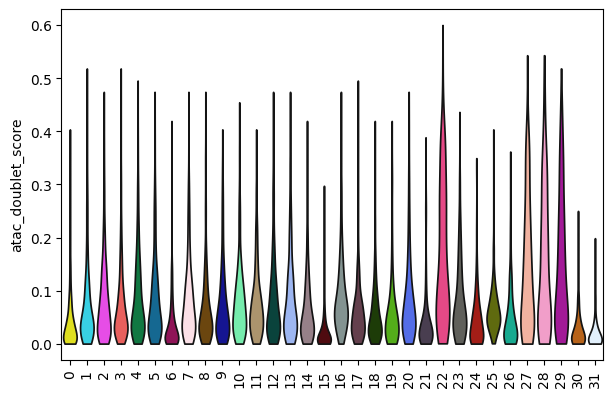

In [31]:
sc.pl.violin(adata, groupby='leiden', keys='atac_doublet_score', size=0, rotation=90)

### 5. Doublet removal

In [32]:
## Clustering with very high resolution to be able to detect doublets
sc.tl.leiden(adata, resolution=100, key_added='v1_leiden_100')

In [33]:
len(adata.obs['v1_leiden_100'].unique())

1368

In [34]:
# adata.obs['souporcell_status'].value_counts()

In [35]:
adata.obs['amulet_doublet'].value_counts()

amulet_doublet
False    15474
True      1802
Name: count, dtype: int64

In [36]:
adata.obs['is_valid_doublet'].value_counts()

is_valid_doublet
0    15474
1     1802
Name: count, dtype: int64

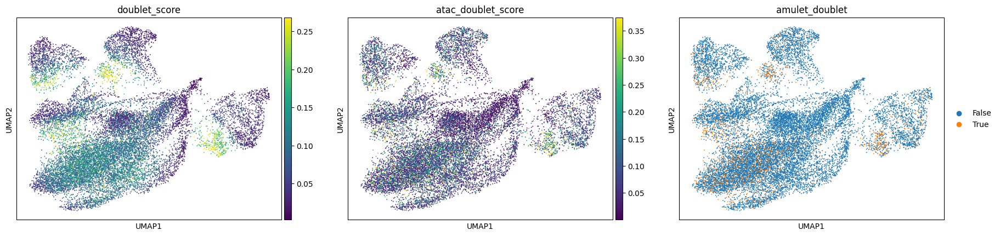

In [37]:
sc.pl.umap(adata, color=['doublet_score', 'atac_doublet_score', 'amulet_doublet'], vmax='p99')

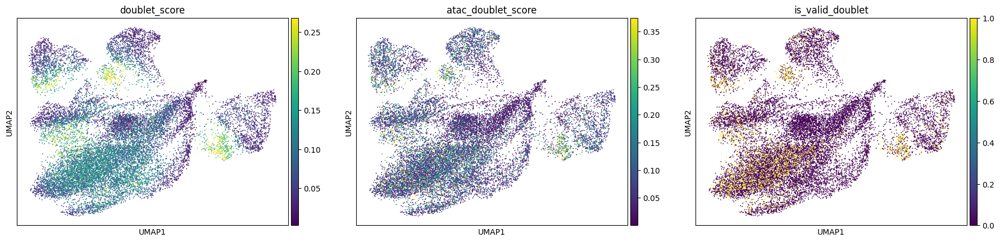

In [38]:
sc.pl.umap(adata, color=['doublet_score', 'atac_doublet_score', 'is_valid_doublet'], vmax='p99')

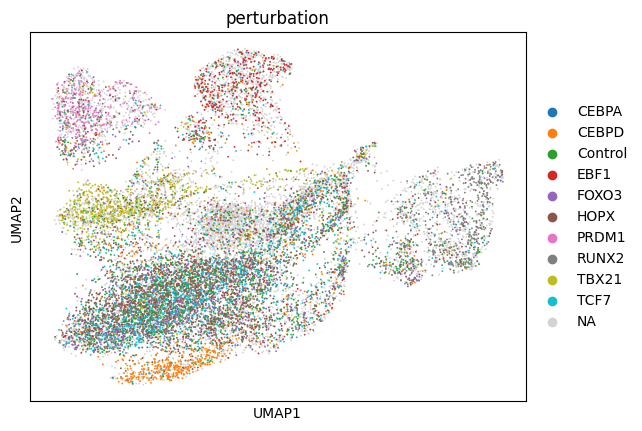

In [39]:
sc.pl.umap(adata, color=['perturbation'], vmax='p99')

In [40]:
adata.obs['amulet_doublet'].value_counts()

amulet_doublet
False    15474
True      1802
Name: count, dtype: int64

In [41]:
# Calculate the mean of the specified columns
mean_stats = adata.obs.groupby('v1_leiden_100')[['doublet_score', 'atac_doublet_score', 'is_valid_doublet']].mean()

# Calculate the size of each group
cluster_sizes = adata.obs.groupby('v1_leiden_100').size()

# Combine the mean values and the cluster sizes into a single DataFrame
overclust_stats = mean_stats.join(cluster_sizes.rename('cluster_size'))

(array([644.,   0.,   1.,   1.,  11.,   9.,  11.,  14.,  27.,  16.,  24.,
         25.,  43.,  45.,   5.,  50.,  14.,  42.,   3.,  14.,  38.,   1.,
         25.,   4.,   0.,  35.,  10.,  18.,   7.,   3.,   0.,  35.,   1.,
          4.,  21.,  21.,   0.,  12.,   2.,   1.,   1.,  26.,   0.,   2.,
          4.,   6.,  19.,   0.,   4.,   0.,  12.,   0.,   3.,  12.,   0.,
          3.,   3.,   3.,   0.,   1.,   0.,   0.,  13.,   0.,   1.,   1.,
          0.,   1.,   4.,   1.,   0.,   1.,   1.,   0.,   0.,   4.,   0.,
          0.,   1.,   0.,   0.,   0.,   0.,   1.,   1.,   1.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          1.]),
 array([0.   , 0.008, 0.016, 0.024, 0.032, 0.04 , 0.048, 0.056, 0.064,
        0.072, 0.08 , 0.088, 0.096, 0.104, 0.112, 0.12 , 0.128, 0.136,
        0.144, 0.152, 0.16 , 0.168, 0.176, 0.184, 0.192, 0.2  , 0.208,
        0.216, 0.224, 0.232, 0.24 , 0.248, 0.256, 0.264, 0.272, 0.28 ,
        0.288, 0.296, 0.304, 0.312

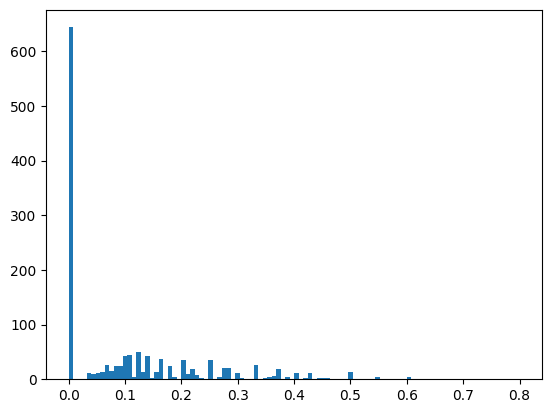

In [42]:
plt.hist(overclust_stats['is_valid_doublet'], bins=100)

(array([ 3.,  4., 13., 16., 11., 20., 24., 16., 20., 30., 35., 22., 28.,
        30., 33., 23., 39., 41., 54., 37., 41., 44., 41., 44., 44., 43.,
        40., 25., 42., 32., 41., 35., 30., 23., 18., 30., 32., 22., 17.,
        17., 20., 12., 13., 14., 12., 13.,  6., 12.,  5., 13.,  7.,  4.,
         7.,  7.,  6.,  7.,  5.,  1.,  2.,  4.,  3.,  7.,  0.,  1.,  3.,
         3.,  3.,  1.,  1.,  1.,  3.,  2.,  1.,  1.,  1.,  1.,  0.,  0.,
         1.,  1.,  0.,  0.,  1.,  0.,  0.,  0.,  0.,  1.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  1.,  0.,  1.]),
 array([0.00512376, 0.00774789, 0.01037201, 0.01299613, 0.01562025,
        0.01824437, 0.02086849, 0.02349261, 0.02611673, 0.02874085,
        0.03136497, 0.03398909, 0.03661321, 0.03923733, 0.04186145,
        0.04448557, 0.04710969, 0.04973381, 0.05235794, 0.05498206,
        0.05760618, 0.0602303 , 0.06285442, 0.06547854, 0.06810266,
        0.07072678, 0.0733509 , 0.07597502, 0.07859914, 0.08122326,
        0.08384738, 0.0864

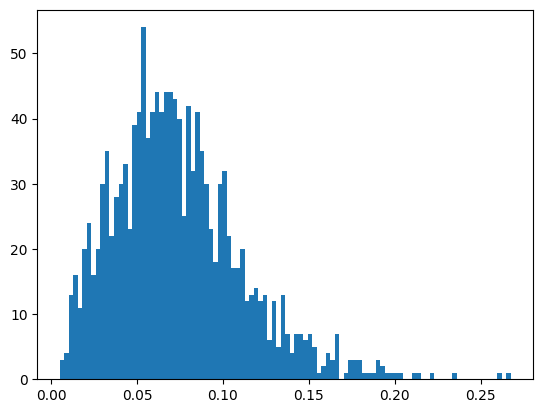

In [43]:
plt.hist(overclust_stats['atac_doublet_score'], bins=100)

(array([ 1.,  0.,  2.,  0.,  7., 14., 18., 19., 19., 19., 19., 34., 33.,
        36., 26., 37., 28., 24., 36., 30., 31., 32., 46., 23., 44., 36.,
        45., 65., 43., 58., 57., 46., 53., 46., 52., 35., 30., 25., 22.,
        23., 15., 16.,  9., 16.,  8.,  6.,  4.,  7.,  6.,  8.,  3.,  4.,
         5.,  3.,  1.,  2.,  0.,  2.,  5.,  2.,  4.,  2.,  1.,  5.,  1.,
         3.,  1.,  2.,  1.,  0.,  1.,  1.,  2.,  1.,  1.,  1.,  1.,  0.,
         0.,  0.,  1.,  0.,  0.,  1.,  1.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  1.]),
 array([0.00419421, 0.00721395, 0.01023368, 0.01325342, 0.01627316,
        0.01929289, 0.02231263, 0.02533236, 0.0283521 , 0.03137183,
        0.03439157, 0.03741131, 0.04043104, 0.04345078, 0.04647051,
        0.04949025, 0.05250999, 0.05552972, 0.05854946, 0.06156919,
        0.06458893, 0.06760866, 0.0706284 , 0.07364814, 0.07666787,
        0.07968761, 0.08270734, 0.08572708, 0.08874681, 0.09176655,
        0.09478629, 0.0978

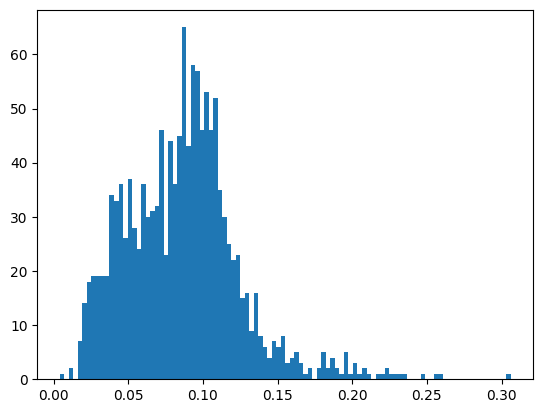

In [44]:
plt.hist(overclust_stats['doublet_score'], bins=100)

(array([  8.,   0.,  30.,   0.,  49.,   0.,  75.,   0.,  99.,   0.,   0.,
        145.,   0., 128.,   0., 121.,   0., 118.,   0.,   0.,  92.,   0.,
         66.,   0.,  67.,   0.,  54.,   0.,  37.,   0.,   0.,  35.,   0.,
         31.,   0.,  26.,   0.,  28.,   0.,   0.,  18.,   0.,  17.,   0.,
         16.,   0.,  10.,   0.,   6.,   0.,   0.,  12.,   0.,  13.,   0.,
          9.,   0.,   7.,   0.,   0.,   7.,   0.,   5.,   0.,   3.,   0.,
          4.,   0.,   6.,   0.,   0.,   6.,   0.,   5.,   0.,   4.,   0.,
          3.,   0.,   0.,   1.,   0.,   1.,   0.,   3.,   0.,   0.,   0.,
          0.,   0.,   0.,   2.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          1.]),
 array([ 3.  ,  3.45,  3.9 ,  4.35,  4.8 ,  5.25,  5.7 ,  6.15,  6.6 ,
         7.05,  7.5 ,  7.95,  8.4 ,  8.85,  9.3 ,  9.75, 10.2 , 10.65,
        11.1 , 11.55, 12.  , 12.45, 12.9 , 13.35, 13.8 , 14.25, 14.7 ,
        15.15, 15.6 , 16.05, 16.5 , 16.95, 17.4 , 17.85, 18.3 , 18.75,
        19.2 , 19.65, 20.1 , 20.55

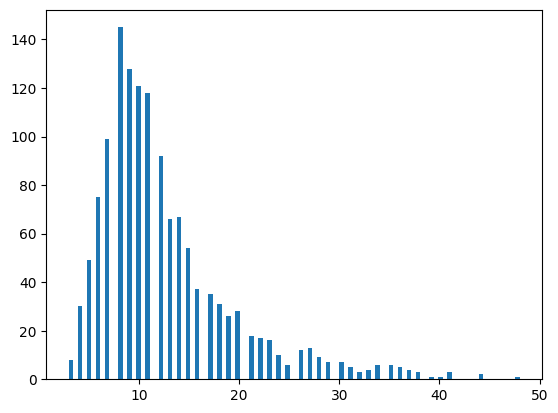

In [45]:
plt.hist(overclust_stats['cluster_size'], bins=100)

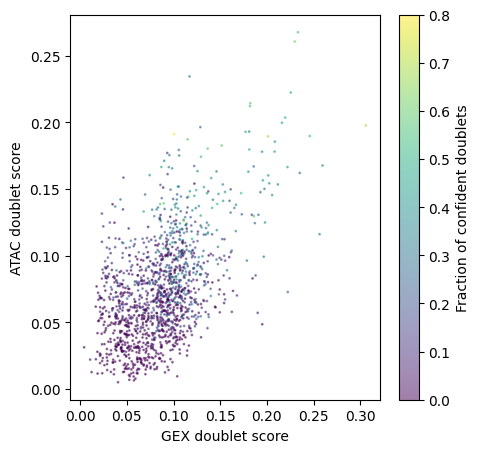

In [46]:
plt.rcParams['figure.figsize'] = [5, 5]
f = plt.scatter(overclust_stats['doublet_score'], overclust_stats['atac_doublet_score'], s=1, alpha=0.5, 
            c=overclust_stats['is_valid_doublet'], cmap='viridis')
plt.xlabel('GEX doublet score')
plt.ylabel('ATAC doublet score')

# Add colorbar to the plot
cbar = plt.colorbar(f)
cbar.set_label('Fraction of confident doublets')

plt.show()

In [47]:
pearsonr(overclust_stats['doublet_score'], overclust_stats['atac_doublet_score'])

PearsonRResult(statistic=0.5235488552842639, pvalue=3.9066304227807556e-97)

In [48]:
pearsonr(overclust_stats['is_valid_doublet'], overclust_stats['atac_doublet_score'])

PearsonRResult(statistic=0.6924371475544643, pvalue=6.7038153643967915e-196)

In [49]:
pearsonr(overclust_stats['is_valid_doublet'], overclust_stats['doublet_score'])

PearsonRResult(statistic=0.5050884087819887, pvalue=1.8495562156983846e-89)

In [50]:
## Generating a consensus score across the 3 metrics
overclust_stats['consensus_doublet_score'] = overclust_stats[['doublet_score', 'atac_doublet_score', 'is_valid_doublet']].mean(axis=1)

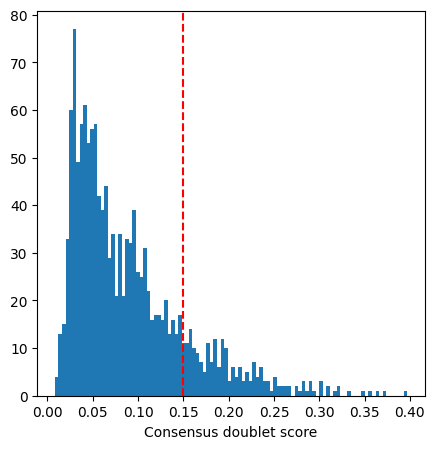

In [51]:
plt.hist(overclust_stats['consensus_doublet_score'], bins=100)
plt.xlabel('Consensus doublet score')
plt.axvline(0.15, c='red', linestyle='--')

In [52]:
overclust_stats

,doublet_score,atac_doublet_score,is_valid_doublet,cluster_size,consensus_doublet_score
v1_leiden_100,,,,,
0,0.021348,0.068172,0.020833,48,0.036784
1,0.222137,0.166455,0.454545,44,0.281046
2,0.102116,0.034690,0.000000,44,0.045602
3,0.020740,0.069898,0.073171,41,0.054603
4,0.033085,0.026311,0.000000,41,0.019798
...,...,...,...,...,...
1363,0.117101,0.234376,0.333333,3,0.228270
1364,0.094959,0.166432,0.333333,3,0.198242
1365,0.095542,0.175419,0.333333,3,0.201431


In [53]:
doub_clust = overclust_stats.index[overclust_stats['consensus_doublet_score'] > 0.15].astype(str)

In [54]:
# sum((adata.obs['v1_leiden_100'].isin(doub_clust)) | (adata.obs['is_valid_doublet']==1)) / adata.obs.shape[0] 
sum(adata.obs['v1_leiden_100'].isin(doub_clust)) / adata.obs.shape[0] # don't remove amulet doublets as it seems to think iPSCs are doublets (chromatin more open?)

0.1390946978467238

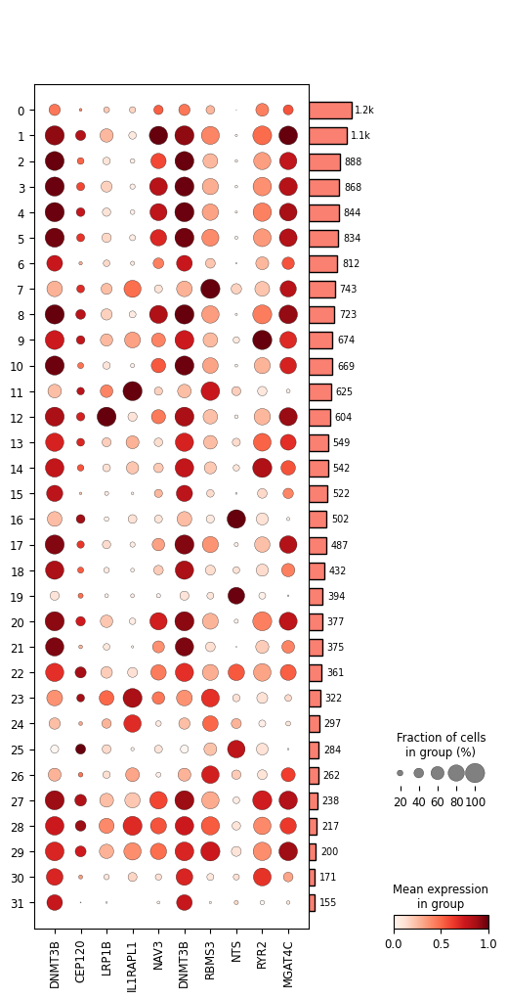

In [55]:
## Let's examine these clusters in terms of expression of conflicting markers
lineage_markers = ['DNMT3B', 'CEP120', 'LRP1B', 'IL1RAPL1', 'NAV3', 'DNMT3B', 'RBMS3', 'NTS', 'RYR2', 'MGAT4C']

sc.pl.DotPlot(adata, 
              lineage_markers,
              groupby=['leiden'],
              standard_scale='var', cmap='Reds').add_totals().show()

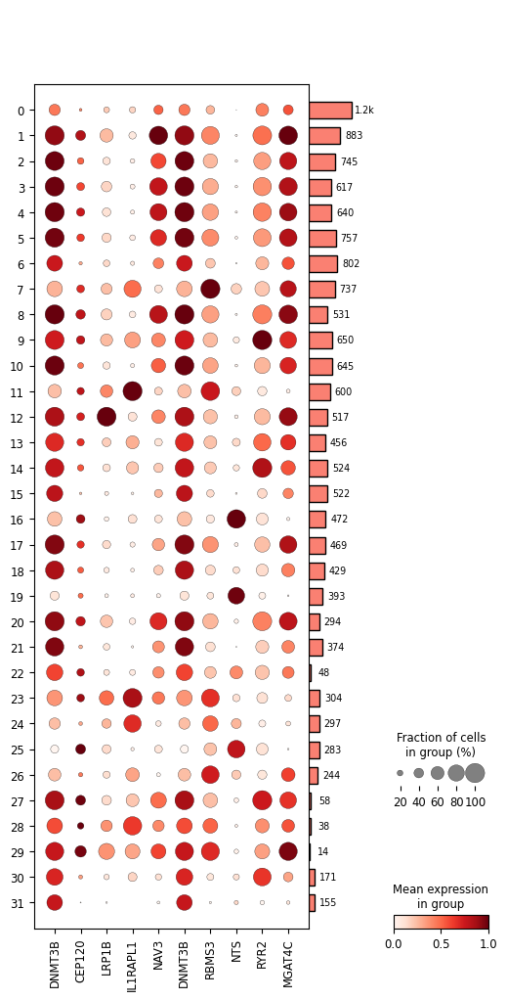

In [56]:
## Excluding doublet-associated clusters
sc.pl.DotPlot(adata[adata.obs['v1_leiden_100'].isin(doub_clust)==False], 
              lineage_markers,
              groupby=['leiden'],
              standard_scale='var', cmap='Reds').add_totals().show()

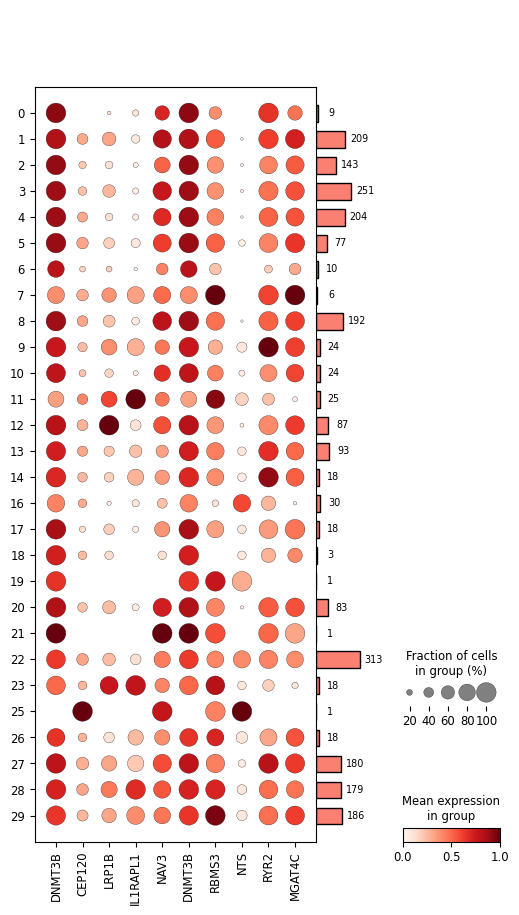

In [57]:
## For comparison, in the remaining clusters
sc.pl.DotPlot(adata[adata.obs['v1_leiden_100'].isin(doub_clust)], 
              lineage_markers,
              groupby=['leiden'],
              standard_scale='var', cmap='Reds').add_totals().show()

In [58]:
## Exporting object before filtering
adata.write_h5ad((output_p + 'adata_leiden_v1.h5ad'))

In [59]:
adata = sc.read_h5ad((output_p + 'adata_leiden_v1.h5ad'))

In [60]:
## Also export the overclustering stats
overclust_stats.to_csv((output_p + 'leiden_100_cluster_stats.csv'))

In [61]:
overclust_stats= pd.read_csv((output_p + 'leiden_100_cluster_stats.csv'))

In [62]:
adata

AnnData object with n_obs × n_vars = 17276 × 36601
    obs: 'sample_barcode', 'barcode', 'gex_barcode', 'atac_barcode', 'cellranger_gex_umis_count', 'cellranger_gex_genes_count', 'snap_atac_fragments', 'snap_TSS_enrichment', 'f_intronic', 'cellranger_is_cell', 'EDM_is_cell', 'multiQC_leiden', 'multiQC_is_cell', 'atac_doublet_score', 'sample_ID', 'n_genes_by_counts', 'total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'amulet_pval', 'amulet_qval', 'enrichment', 'sample_description', 'Control_pos2', 'CEBPA_pos2', 'CEBPD_pos2', 'EBF1_pos2', 'FOXO3_pos2', 'HOPX_pos2', 'PRDM1_pos2', 'RUNX2_pos2', 'TBX21_pos2', 'TCF7_pos2', 'max', 'perturbation', 'leiden', 'amulet_doublet', 'is_valid_doublet', 'v1_leiden_100'
    var: 'highly_variable', 'means', 'dispersions'

In [63]:
adata_filt = adata[(adata.obs['v1_leiden_100'].isin(doub_clust)==False) & (adata.obs['is_valid_doublet']==0)].copy()

In [64]:
adata_filt

AnnData object with n_obs × n_vars = 13978 × 36601
    obs: 'sample_barcode', 'barcode', 'gex_barcode', 'atac_barcode', 'cellranger_gex_umis_count', 'cellranger_gex_genes_count', 'snap_atac_fragments', 'snap_TSS_enrichment', 'f_intronic', 'cellranger_is_cell', 'EDM_is_cell', 'multiQC_leiden', 'multiQC_is_cell', 'atac_doublet_score', 'sample_ID', 'n_genes_by_counts', 'total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'amulet_pval', 'amulet_qval', 'enrichment', 'sample_description', 'Control_pos2', 'CEBPA_pos2', 'CEBPD_pos2', 'EBF1_pos2', 'FOXO3_pos2', 'HOPX_pos2', 'PRDM1_pos2', 'RUNX2_pos2', 'TBX21_pos2', 'TCF7_pos2', 'max', 'perturbation', 'leiden', 'amulet_doublet', 'is_valid_doublet', 'v1_leiden_100'
    var: 'highly_variable', 'means', 'dispersions'

In [65]:
# ## Additionally excluding NA and unknown donors
# adata_filt = adata_filt[adata_filt.obs['donor'].isna()==False]
# adata_filt = adata_filt[adata_filt.obs['donor']!='unknown']

In [66]:
adata_filt

AnnData object with n_obs × n_vars = 13978 × 36601
    obs: 'sample_barcode', 'barcode', 'gex_barcode', 'atac_barcode', 'cellranger_gex_umis_count', 'cellranger_gex_genes_count', 'snap_atac_fragments', 'snap_TSS_enrichment', 'f_intronic', 'cellranger_is_cell', 'EDM_is_cell', 'multiQC_leiden', 'multiQC_is_cell', 'atac_doublet_score', 'sample_ID', 'n_genes_by_counts', 'total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'amulet_pval', 'amulet_qval', 'enrichment', 'sample_description', 'Control_pos2', 'CEBPA_pos2', 'CEBPD_pos2', 'EBF1_pos2', 'FOXO3_pos2', 'HOPX_pos2', 'PRDM1_pos2', 'RUNX2_pos2', 'TBX21_pos2', 'TCF7_pos2', 'max', 'perturbation', 'leiden', 'amulet_doublet', 'is_valid_doublet', 'v1_leiden_100'
    var: 'highly_variable', 'means', 'dispersions'

Text(0, 0.5, 'Cell count')

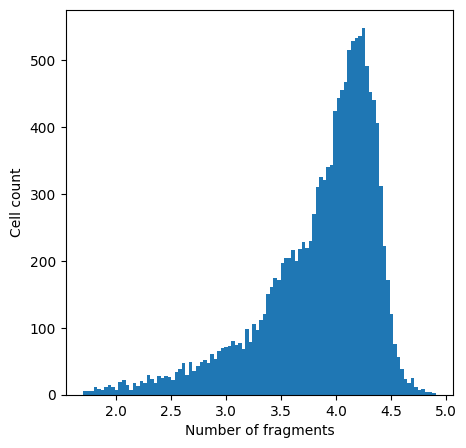

In [67]:
plt.hist(np.log10(adata_filt.obs['snap_atac_fragments']), bins=100)
plt.xlabel('Number of fragments')
plt.ylabel('Cell count')

In [68]:
adata_filt.obs['snap_atac_fragments'].describe()

count    13978.000000
mean     11509.027758
std       9062.976612
min         50.000000
25%       4013.750000
50%      10078.000000
75%      16936.000000
max      80555.000000
Name: snap_atac_fragments, dtype: float64

Text(0, 0.5, 'Cell count')

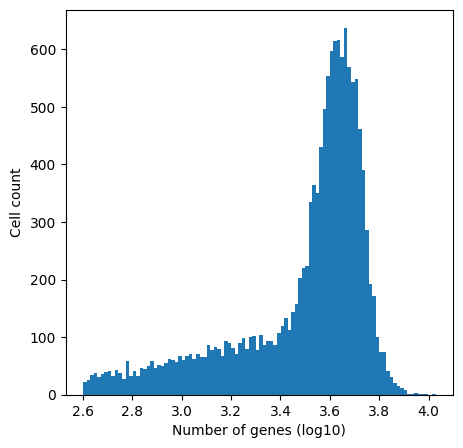

In [69]:
plt.hist(np.log10(adata_filt.obs['n_genes_by_counts']), bins=100)
plt.xlabel('Number of genes (log10)')
plt.ylabel('Cell count')

In [70]:
adata_filt.obs['n_genes_by_counts'].describe()

count    13978.000000
mean      3590.394262
std       1565.438850
min        400.000000
25%       2485.500000
50%       3896.000000
75%       4706.000000
max      10659.000000
Name: n_genes_by_counts, dtype: float64

Text(0, 0.5, 'Cell count')

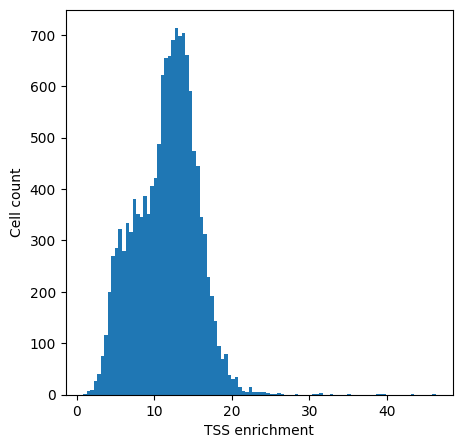

In [71]:
plt.hist(adata_filt.obs['snap_TSS_enrichment'], bins=100)
plt.xlabel('TSS enrichment')
plt.ylabel('Cell count')

Text(0, 0.5, 'Cell count')

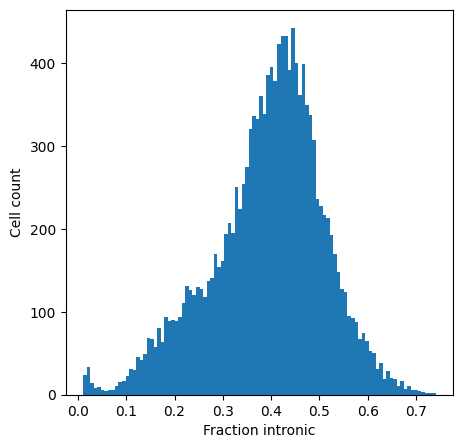

In [75]:
plt.hist(adata_filt.obs['f_intronic'], bins=100)
plt.xlabel('Fraction intronic')
plt.ylabel('Cell count')

Text(0, 0.5, 'Cell count')

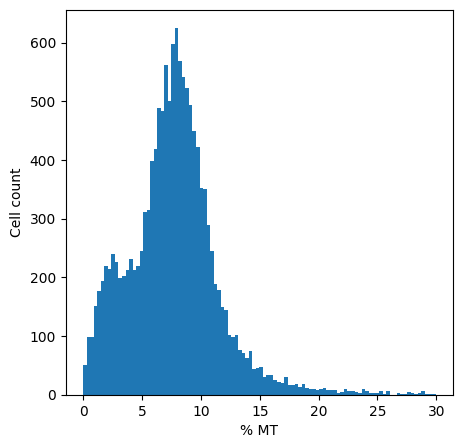

In [76]:
plt.hist(adata_filt.obs['pct_counts_mt'], bins=100)
plt.xlabel('% MT')
plt.ylabel('Cell count')

In [72]:
adata_filt.obs['snap_TSS_enrichment'].describe()

count    13978.000000
mean        11.541111
std          3.919119
min          0.826446
25%          8.720634
50%         11.932448
75%         14.231516
max         46.280992
Name: snap_TSS_enrichment, dtype: float64

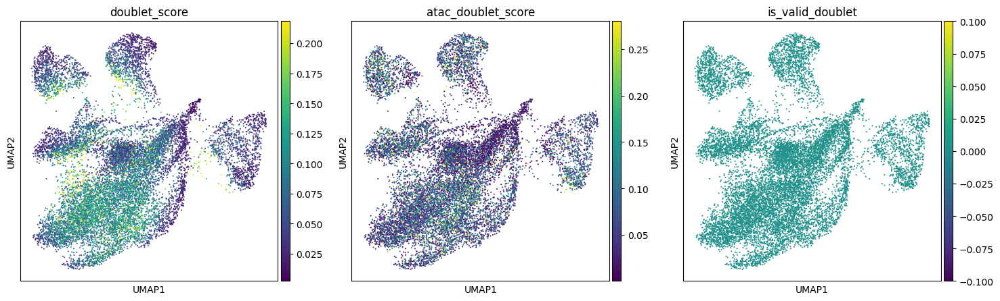

In [73]:
sc.pl.umap(adata_filt, color=['doublet_score', 'atac_doublet_score', 'is_valid_doublet'], vmax='p99')

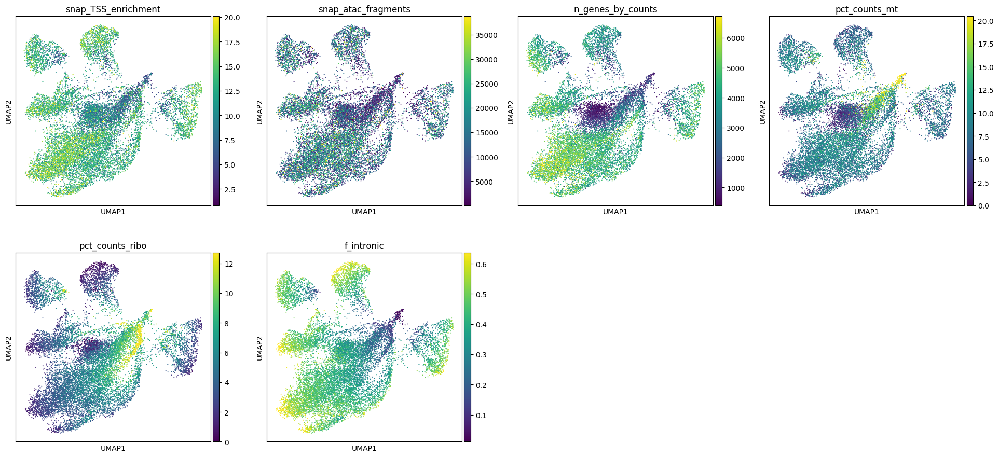

In [74]:
sc.pl.umap(adata_filt, color=['snap_TSS_enrichment', 'snap_atac_fragments', 'n_genes_by_counts', 'pct_counts_mt', 'pct_counts_ribo', 'f_intronic'], vmax='p99')

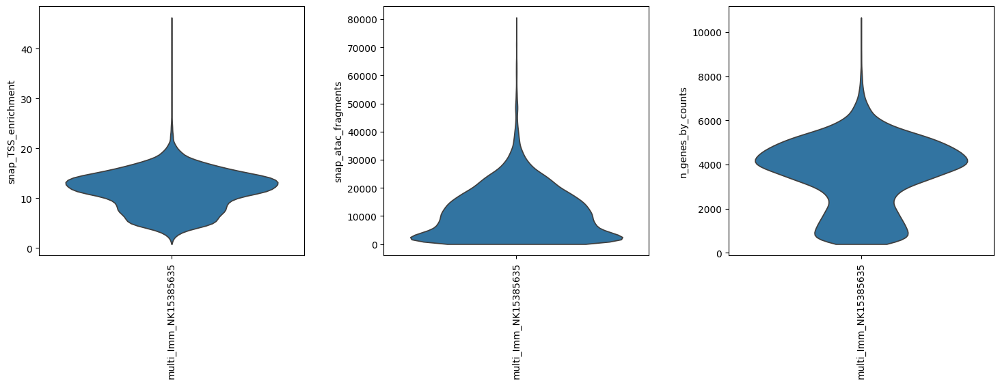

In [73]:
sc.pl.violin(adata_filt, groupby='sample_ID',keys=['snap_TSS_enrichment', 'snap_atac_fragments', 'n_genes_by_counts'], size=0, rotation=90)

In [77]:
## Also filtering out nuclei with less than 500 fragments, more than 100,000 fragments, TSS enrichment < 5 and more than 10,000 genes.
adata_filt = adata_filt[(adata_filt.obs['snap_atac_fragments'] >= 500) & 
(adata_filt.obs['snap_atac_fragments'] <= 100000) & 
(adata_filt.obs['snap_TSS_enrichment'] >= 5) & 
(adata_filt.obs['n_genes_by_counts'] <= 10000) & 
(adata_filt.obs['n_genes_by_counts'] > 2500) & 
(adata_filt.obs['f_intronic'] > 0.1)]

In [78]:
adata_filt

View of AnnData object with n_obs × n_vars = 9942 × 36601
    obs: 'sample_barcode', 'barcode', 'gex_barcode', 'atac_barcode', 'cellranger_gex_umis_count', 'cellranger_gex_genes_count', 'snap_atac_fragments', 'snap_TSS_enrichment', 'f_intronic', 'cellranger_is_cell', 'EDM_is_cell', 'multiQC_leiden', 'multiQC_is_cell', 'atac_doublet_score', 'sample_ID', 'n_genes_by_counts', 'total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'amulet_pval', 'amulet_qval', 'enrichment', 'sample_description', 'Control_pos2', 'CEBPA_pos2', 'CEBPD_pos2', 'EBF1_pos2', 'FOXO3_pos2', 'HOPX_pos2', 'PRDM1_pos2', 'RUNX2_pos2', 'TBX21_pos2', 'TCF7_pos2', 'max', 'perturbation', 'leiden', 'amulet_doublet', 'is_valid_doublet', 'v1_leiden_100'
    var: 'highly_variable', 'means', 'dispe

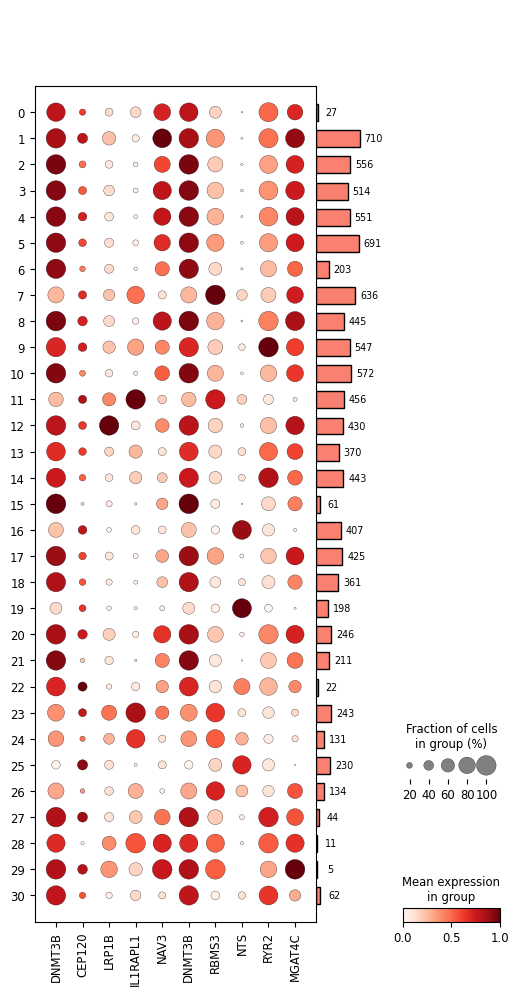

In [79]:
sc.pl.DotPlot(adata_filt, 
              lineage_markers,
              groupby=['leiden'],
              standard_scale='var', cmap='Reds').add_totals().show()

In [80]:
adata

AnnData object with n_obs × n_vars = 17276 × 36601
    obs: 'sample_barcode', 'barcode', 'gex_barcode', 'atac_barcode', 'cellranger_gex_umis_count', 'cellranger_gex_genes_count', 'snap_atac_fragments', 'snap_TSS_enrichment', 'f_intronic', 'cellranger_is_cell', 'EDM_is_cell', 'multiQC_leiden', 'multiQC_is_cell', 'atac_doublet_score', 'sample_ID', 'n_genes_by_counts', 'total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'amulet_pval', 'amulet_qval', 'enrichment', 'sample_description', 'Control_pos2', 'CEBPA_pos2', 'CEBPD_pos2', 'EBF1_pos2', 'FOXO3_pos2', 'HOPX_pos2', 'PRDM1_pos2', 'RUNX2_pos2', 'TBX21_pos2', 'TCF7_pos2', 'max', 'perturbation', 'leiden', 'amulet_doublet', 'is_valid_doublet', 'v1_leiden_100'
    var: 'highly_variable', 'means', 'dispersions'

In [81]:
adata_filt

View of AnnData object with n_obs × n_vars = 9942 × 36601
    obs: 'sample_barcode', 'barcode', 'gex_barcode', 'atac_barcode', 'cellranger_gex_umis_count', 'cellranger_gex_genes_count', 'snap_atac_fragments', 'snap_TSS_enrichment', 'f_intronic', 'cellranger_is_cell', 'EDM_is_cell', 'multiQC_leiden', 'multiQC_is_cell', 'atac_doublet_score', 'sample_ID', 'n_genes_by_counts', 'total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'amulet_pval', 'amulet_qval', 'enrichment', 'sample_description', 'Control_pos2', 'CEBPA_pos2', 'CEBPD_pos2', 'EBF1_pos2', 'FOXO3_pos2', 'HOPX_pos2', 'PRDM1_pos2', 'RUNX2_pos2', 'TBX21_pos2', 'TCF7_pos2', 'max', 'perturbation', 'leiden', 'amulet_doublet', 'is_valid_doublet', 'v1_leiden_100'
    var: 'highly_variable', 'means', 'dispe

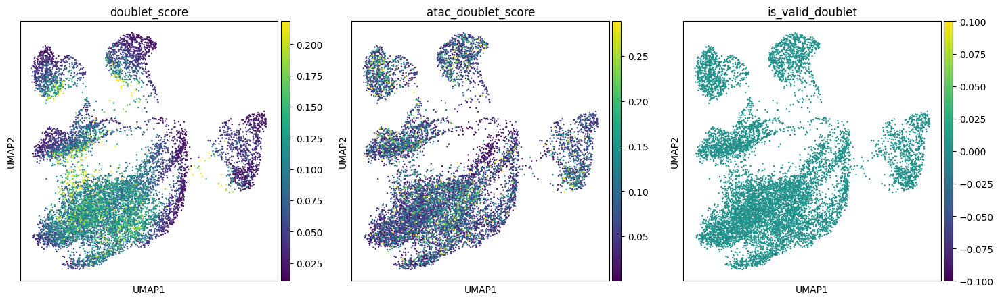

In [82]:
sc.pl.umap(adata_filt, color=['doublet_score', 'atac_doublet_score', 'is_valid_doublet'], vmax='p99')

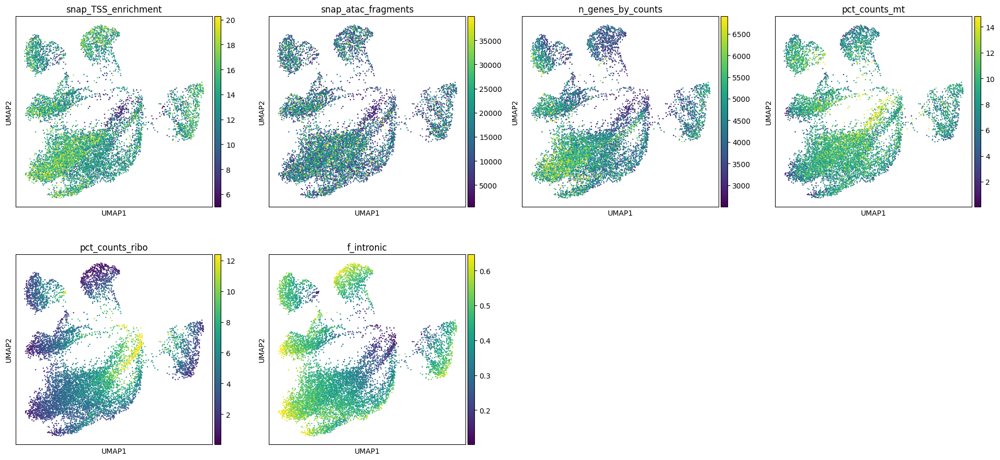

In [83]:
sc.pl.umap(adata_filt, color=['snap_TSS_enrichment', 'snap_atac_fragments', 'n_genes_by_counts', 'pct_counts_mt', 'pct_counts_ribo', 'f_intronic'], vmax='p99')

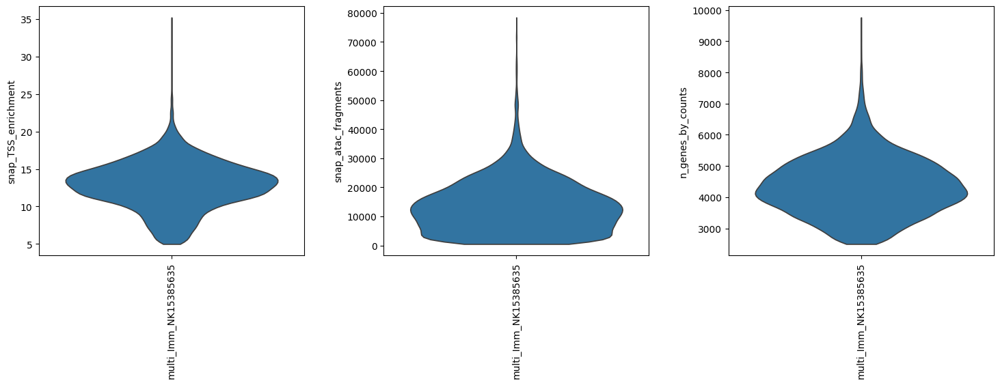

In [84]:
sc.pl.violin(adata_filt, groupby='sample_ID',keys=['snap_TSS_enrichment', 'snap_atac_fragments', 'n_genes_by_counts'], size=0, rotation=90)

In [85]:
## This is our first filtered version - exporting
adata_filt.write_h5ad((output_p + 'adata_v1_filtered.h5ad'))

/software/conda/users/od5/scvi_24/lib/python3.9/site-packages/scanpy/tools/_leiden.py:199: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[key_added] = pd.Categorical(


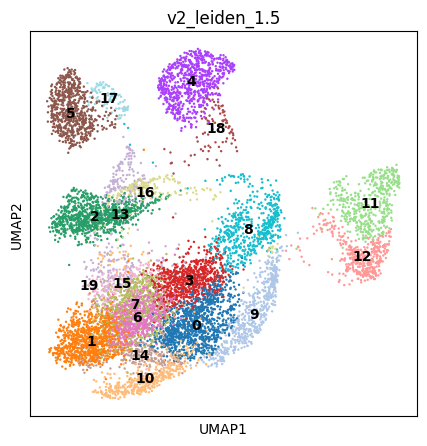

In [86]:
## Annotating at a very broad level
# rsc.tl.leiden(adata, resolution=1.5, key_added='scVI_v2_leiden_1.5')
sc.tl.leiden(adata_filt, resolution=1.5, key_added='v2_leiden_1.5')
sc.pl.umap(adata_filt, color=['v2_leiden_1.5'], legend_loc='on data')

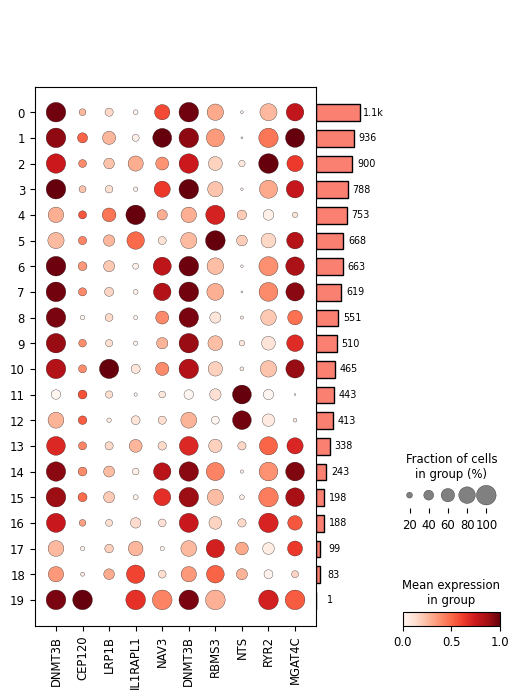

In [87]:
## Let's examine these clusters

sc.pl.DotPlot(adata_filt, 
              lineage_markers,
              groupby=['v2_leiden_1.5'],
              standard_scale='var', cmap='Reds').add_totals().show()

In [88]:
adata_filt

AnnData object with n_obs × n_vars = 9942 × 36601
    obs: 'sample_barcode', 'barcode', 'gex_barcode', 'atac_barcode', 'cellranger_gex_umis_count', 'cellranger_gex_genes_count', 'snap_atac_fragments', 'snap_TSS_enrichment', 'f_intronic', 'cellranger_is_cell', 'EDM_is_cell', 'multiQC_leiden', 'multiQC_is_cell', 'atac_doublet_score', 'sample_ID', 'n_genes_by_counts', 'total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'amulet_pval', 'amulet_qval', 'enrichment', 'sample_description', 'Control_pos2', 'CEBPA_pos2', 'CEBPD_pos2', 'EBF1_pos2', 'FOXO3_pos2', 'HOPX_pos2', 'PRDM1_pos2', 'RUNX2_pos2', 'TBX21_pos2', 'TCF7_pos2', 'max', 'perturbation', 'leiden', 'amulet_doublet', 'is_valid_doublet', 'v1_leiden_100', 'v2_leiden_1.5'
    var: 'highly_variable', 'means

In [89]:
adata_filt[(adata_filt.obs['doublet_score'] < 0.2) & (adata_filt.obs['atac_doublet_score'] < 0.2)]

View of AnnData object with n_obs × n_vars = 9379 × 36601
    obs: 'sample_barcode', 'barcode', 'gex_barcode', 'atac_barcode', 'cellranger_gex_umis_count', 'cellranger_gex_genes_count', 'snap_atac_fragments', 'snap_TSS_enrichment', 'f_intronic', 'cellranger_is_cell', 'EDM_is_cell', 'multiQC_leiden', 'multiQC_is_cell', 'atac_doublet_score', 'sample_ID', 'n_genes_by_counts', 'total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'amulet_pval', 'amulet_qval', 'enrichment', 'sample_description', 'Control_pos2', 'CEBPA_pos2', 'CEBPD_pos2', 'EBF1_pos2', 'FOXO3_pos2', 'HOPX_pos2', 'PRDM1_pos2', 'RUNX2_pos2', 'TBX21_pos2', 'TCF7_pos2', 'max', 'perturbation', 'leiden', 'amulet_doublet', 'is_valid_doublet', 'v1_leiden_100', 'v2_leiden_1.5'
    var: 'highly_variable'

In [90]:
adata_filt.obs['sample_ID'][(adata_filt.obs['doublet_score'] < 0.2) & (adata_filt.obs['atac_doublet_score'] < 0.2)].value_counts()

sample_ID
multi_Imm_NK15385635    9379
Name: count, dtype: int64

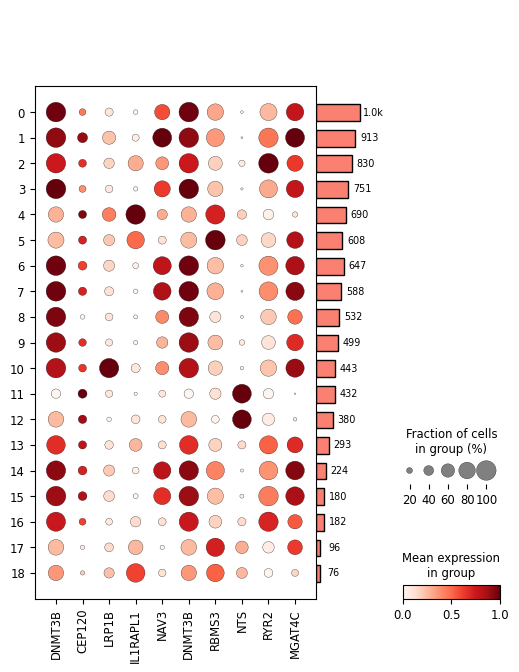

In [91]:
sc.pl.DotPlot(adata_filt[(adata_filt.obs['doublet_score'] < 0.2) & (adata_filt.obs['atac_doublet_score'] < 0.2)], 
              lineage_markers,
              groupby=['v2_leiden_1.5'],
              standard_scale='var', cmap='Reds').add_totals().show()

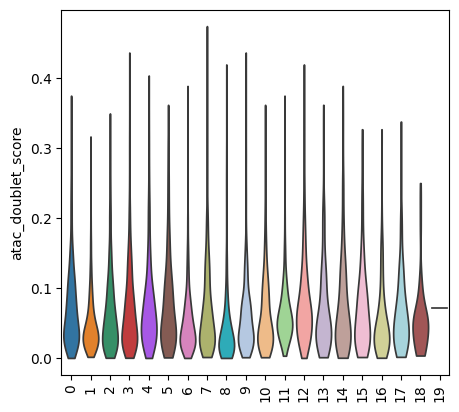

In [92]:
sc.pl.violin(adata_filt, groupby='v2_leiden_1.5', keys='atac_doublet_score', size=0, rotation=90)

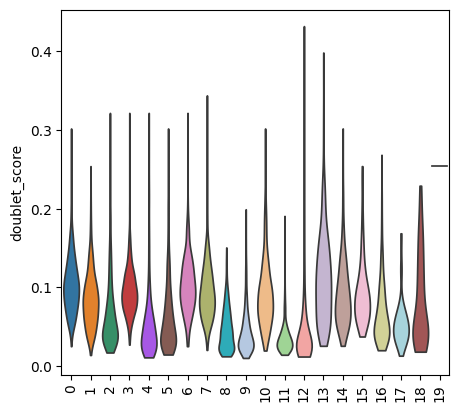

In [93]:
sc.pl.violin(adata_filt, groupby='v2_leiden_1.5', keys='doublet_score', size=0, rotation=90)

## Annotate

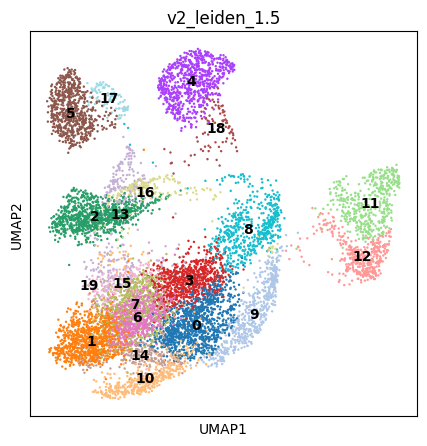

In [94]:
sc.pl.umap(adata_filt, color=['v2_leiden_1.5'], legend_loc='on data')

In [95]:
# ## Annotate
# clust_labs = {'0': 'iPSC', '1': 'Monocyte_macrophage', '2': 'iPSC', '3': 'Monocyte_macrophage', '4': 'iPSC',
#               '5': 'iPSC', '6': 'iPSC', '7': 'iPSC',
#              '8': 'iPSC', '9': 'Monocyte_macrophage', '10': 'iPSC', '11': 'iPSC',
#               '12': 'Monocyte_macrophage', '13': 'iPSC', '14': 'Mast',
#              '15': 'NK', '16': 'iPSC', '17': 'iPSC',
#              '18': 'iPSC', '19': 'Mast', '20': 'iPSC', 
#              '21': 'DC', '22': 'ILC', '23': 'iPSC'}


In [96]:
# adata_filt.obs['anno_v1_nuc_gex'] = adata_filt.obs['v2_leiden_1.5'].map(clust_labs)
adata_filt.obs['anno_v1_nuc_gex'] = "iPSC"

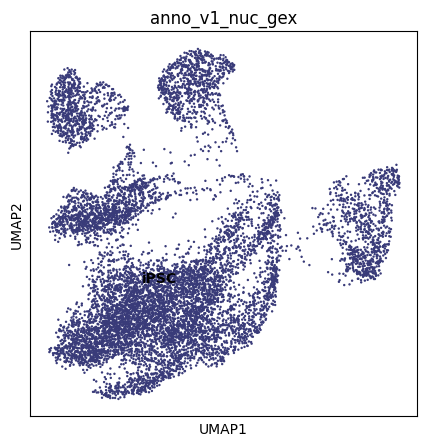

In [97]:
sc.pl.umap(adata_filt, color=['anno_v1_nuc_gex'], legend_loc='on data', palette='tab20b')

In [98]:
## Find neighbors, run Leiden clustering and UMAP

sc.pp.highly_variable_genes(adata_filt)
sc.pp.pca(adata_filt)

sc.pp.neighbors(adata_filt)

In [99]:
sc.tl.leiden(adata_filt, resolution=1.5, key_added='v3_leiden_1.5')

In [100]:
sc.tl.umap(adata_filt)

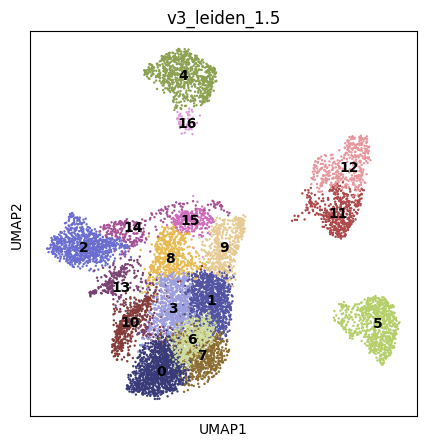

In [101]:
sc.pl.umap(adata_filt, color=['v3_leiden_1.5'], legend_loc='on data', palette='tab20b')

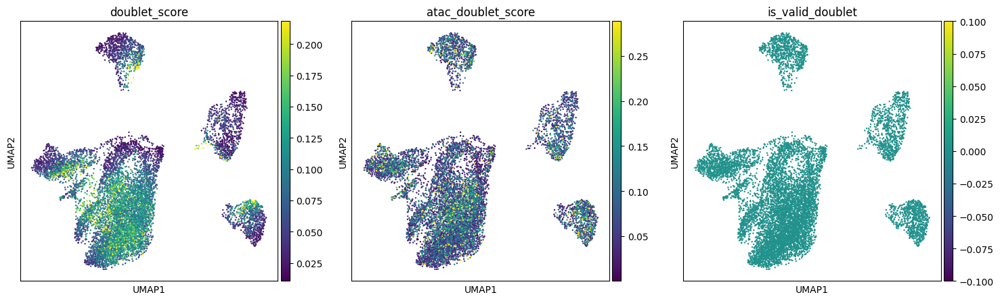

In [102]:
sc.pl.umap(adata_filt, color=['doublet_score', 'atac_doublet_score', 'is_valid_doublet'], vmax='p99')

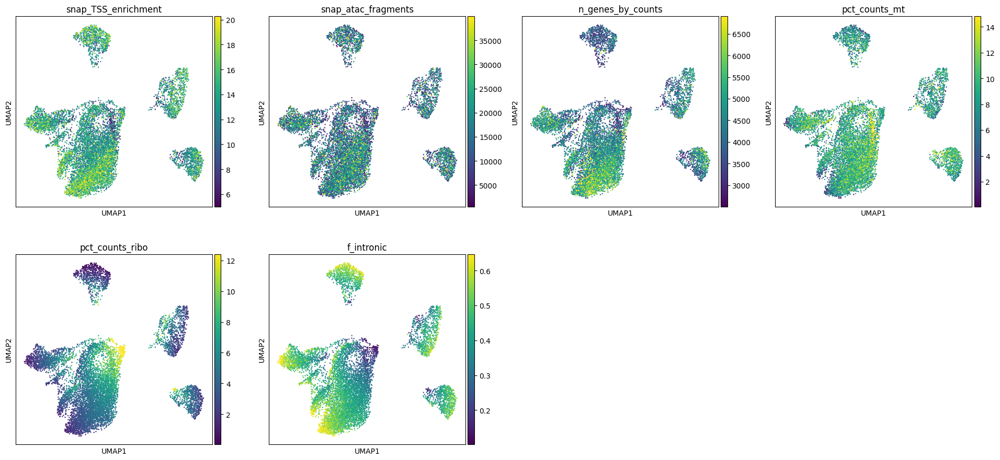

In [105]:
sc.pl.umap(adata_filt, color=['snap_TSS_enrichment', 'snap_atac_fragments', 'n_genes_by_counts', 'pct_counts_mt', 'pct_counts_ribo', 'f_intronic'], vmax='p99')

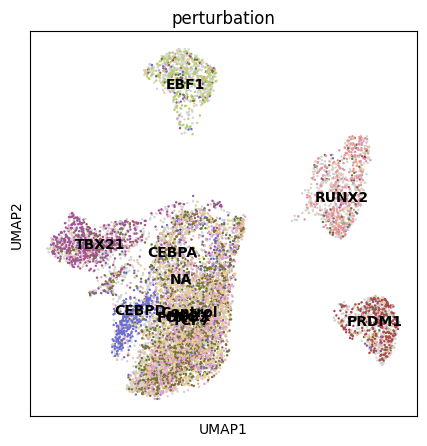

In [104]:
sc.pl.umap(adata_filt, color=['perturbation'], legend_loc='on data', palette='tab20b')

In [106]:
sc.tl.leiden(adata_filt, resolution=1, key_added='v3_leiden_1')

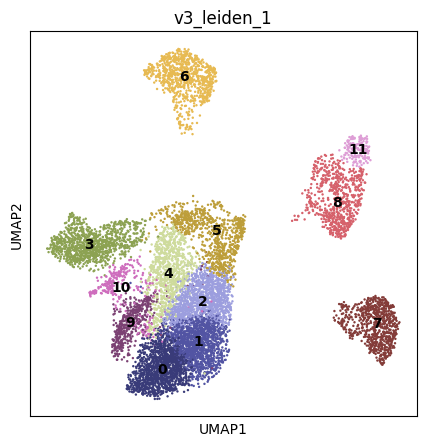

In [107]:
sc.pl.umap(adata_filt, color=['v3_leiden_1'], legend_loc='on data', palette='tab20b')

In [110]:
sc.tl.leiden(adata_filt, resolution=0.8, key_added='v3_leiden_0.8')

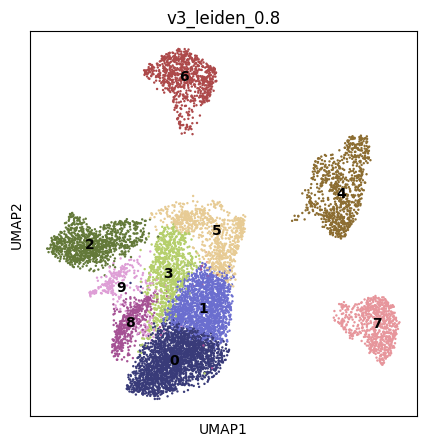

In [111]:
sc.pl.umap(adata_filt, color=['v3_leiden_0.8'], legend_loc='on data', palette='tab20b')

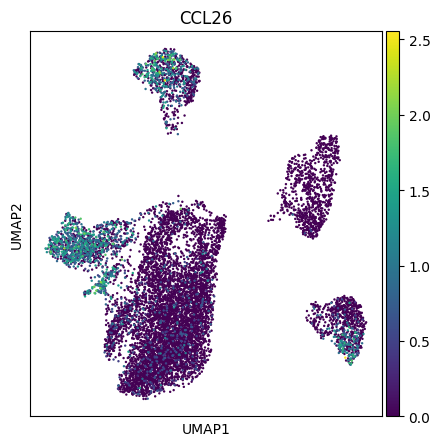

In [117]:
sc.pl.umap(adata_filt, color=['CCL26'])

## Finding marker genes

In [134]:
# sc.pp.scale(adata_filt, max_value=10)

In [113]:
sc.tl.rank_genes_groups(adata_filt, 'v3_leiden_0.8', method = 'wilcoxon')

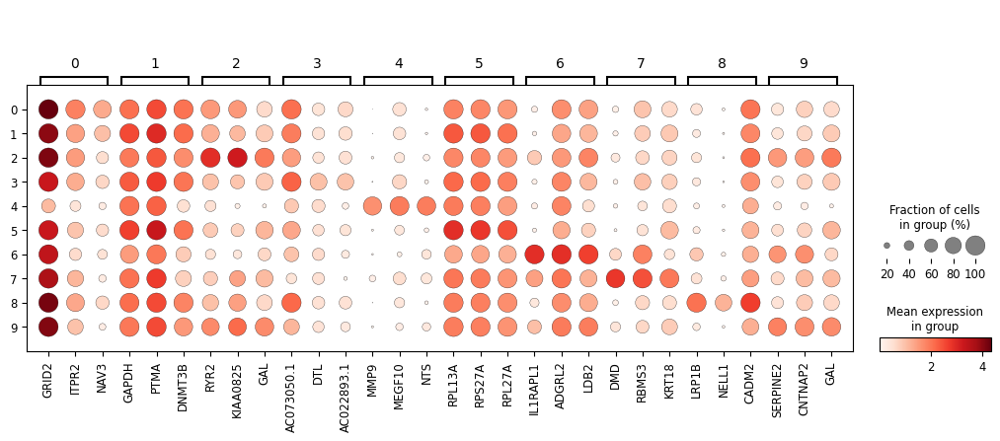

In [114]:
sc.pl.rank_genes_groups_dotplot(adata_filt, swap_axes=False, dendrogram=False, n_genes=3)

In [115]:
pd.DataFrame(adata_filt.uns['rank_genes_groups']['names']).head(60)

,0,1,2,3,4,5,6,7,8,9
0,GRID2,GAPDH,RYR2,AC073050.1,MMP9,RPL13A,IL1RAPL1,DMD,LRP1B,SERPINE2
1,ITPR2,PTMA,KIAA0825,DTL,MEGF10,RPS27A,ADGRL2,RBMS3,NELL1,CNTNAP2
2,NAV3,DNMT3B,GAL,AC022893.1,NTS,RPL27A,LDB2,KRT18,CADM2,GAL
3,JARID2,RPL11,AC005062.1,RMST,SLC7A5,RPS24,MAML3,KRT8,NR6A1,AC068587.4
4,TMEM132B,RPS27A,PWRN1,AL354821.1,TPM1,RPL19,ANK2,HPGD,IDO1,LRFN5
5,GULP1,PEBP1,APP,GRIA4,TMEM163,RPS15,PCDH7,AL157944.1,ROR1,GPC6
6,CALN1,RPS2,SERPINE2,JARID2,KIF26B,RPL17,SLIT2,PCAT14,SORCS1,AC003975.1
7,PCNX2,RPL8,LINC00458,CD24,COL2A1,RPL28,ROR2,EFNA5,FAM155A,GJA1
8,AASS,RPS24,AC003975.1,AP002026.1,NRXN3,RPLP1,FBN2,MMP16,JAKMIP2-AS1,DTWD2
9,RMST,RPL13,GDF3,GABPB1-AS1,ZEB2,RPL23,AUTS2,PRSS12,GULP1,SLIT2


In [119]:
## Annotate
clust_labs = {'0': 'Unperturbed', '1': 'Unperturbed', '2': 'TBX21', '3': 'Unperturbed', '4': 'RUNX2',
              '5': 'Unperturbed', '6': 'EBF1', '7': 'PRDM1',
             '8': 'CEBPD', '9': 'Unperturbed'}


In [120]:
adata_filt.obs['anno_v1_nuc_gex'] = adata_filt.obs['v3_leiden_0.8'].map(clust_labs)

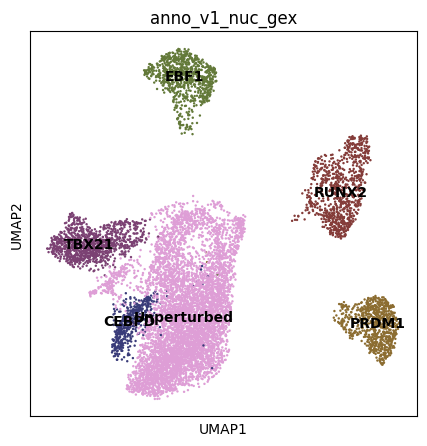

In [121]:
sc.pl.umap(adata_filt, color=['anno_v1_nuc_gex'], legend_loc='on data', palette='tab20b')

In [122]:
## Exporting
adata_filt.write_h5ad((output_p + 'adata_leiden_v3.h5ad'))

In [123]:
## And export full annotation
adata_filt.obs.to_csv(output_p + 'adata_multi_anno_v1_nuc_gex.csv')

In [124]:
adata_filt.layers['counts'].shape

(9942, 36601)

In [125]:
adata_filt

AnnData object with n_obs × n_vars = 9942 × 36601
    obs: 'sample_barcode', 'barcode', 'gex_barcode', 'atac_barcode', 'cellranger_gex_umis_count', 'cellranger_gex_genes_count', 'snap_atac_fragments', 'snap_TSS_enrichment', 'f_intronic', 'cellranger_is_cell', 'EDM_is_cell', 'multiQC_leiden', 'multiQC_is_cell', 'atac_doublet_score', 'sample_ID', 'n_genes_by_counts', 'total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'amulet_pval', 'amulet_qval', 'enrichment', 'sample_description', 'Control_pos2', 'CEBPA_pos2', 'CEBPD_pos2', 'EBF1_pos2', 'FOXO3_pos2', 'HOPX_pos2', 'PRDM1_pos2', 'RUNX2_pos2', 'TBX21_pos2', 'TCF7_pos2', 'max', 'perturbation', 'leiden', 'amulet_doublet', 'is_valid_doublet', 'v1_leiden_100', 'v2_leiden_1.5', 'anno_v1_nuc_gex', 'v3_leiden_1.5